# Analisis Data Titanic

Notebook ini berisi eksplorasi data penumpang Titanic dan persiapan fitur untuk memprediksi apakah seorang penumpang selamat. Dataset yang digunakan adalah `titanic.csv`.

Pengerjaan mencakup ringkasan data, visualisasi, pencatatan pola yang terlihat, penanganan nilai kosong, encoding kategori, dan standardisasi fitur numerik. Di bagian akhir, model Logistic Regression dilatih dan dievaluasi.


## 1. Import Libraries & Load Dataset

In [25]:
# Import library data science dan visualisasi
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Library untuk preprocessing dan evaluasi model
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, confusion_matrix

# Konfigurasi plot
%matplotlib inline
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11



In [26]:
# Load dataset titanic.csv
df = pd.read_csv('titanic.csv')

# Menampilkan 5 baris pertama data
print(f"Dimensi dataset: {df.shape[0]} baris dan {df.shape[1]} kolom\n")
df.head()


Dimensi dataset: 891 baris dan 12 kolom



,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Exploratory Data Analysis

### 2.1 Memahami Data

Sebelum membuat visualisasi, kita periksa tipe data, jumlah nilai kosong, dan statistik ringkas. Kolom `Survived` menjadi target (0 = tidak selamat, 1 = selamat). `Pclass` menunjukkan kelas tiket; `Sex`, `Embarked`, dan `Title` berisi kategori; sedangkan `Age`, `Fare`, `SibSp`, dan `Parch` menggambarkan usia, tarif, serta anggota keluarga di kapal.

`PassengerId` adalah nomor identitas. `Name`, `Ticket`, dan `Cabin` merupakan informasi teks/identitas yang akan ditinjau sebelum pemodelan.


In [27]:
# Struktur dan tipe data
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB


In [28]:
# Cek missing values dan duplikat
missing_df = pd.DataFrame({
    'Missing_Count': df.isnull().sum(),
    'Missing_Percentage (%)': (df.isnull().sum() / len(df) * 100).round(2),
    'Data_Type': df.dtypes
})
print("=== Ringkasan Missing Values & Duplikat ===")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}\n")
missing_df


=== Ringkasan Missing Values & Duplikat ===
Jumlah baris duplikat: 0



,Missing_Count,Missing_Percentage (%),Data_Type
PassengerId,0,0.00,int64
Survived,0,0.00,int64
Pclass,0,0.00,int64
Name,0,0.00,str
Sex,0,0.00,str
Age,177,19.87,float64
SibSp,0,0.00,int64
Parch,0,0.00,int64
Ticket,0,0.00,str
Fare,0,0.00,float64


In [29]:
# Statistik Deskriptif Fitur Numerik
df.describe()


,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [30]:
# Statistik Deskriptif Fitur Kategorikal
df.describe(include=['O'])


C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\2758259570.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include=['O'])


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


=== Distribusi Target (Survived) ===
Tidak Selamat (0): 549 (61.62%)
Selamat (1)      : 342 (38.38%)


C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\3578148812.py:18: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='Survived', palette=colors, ax=ax[1])
C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\3578148812.py:20: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  ax[1].set_xticklabels(['Tidak Selamat (0)', 'Selamat (1)'])


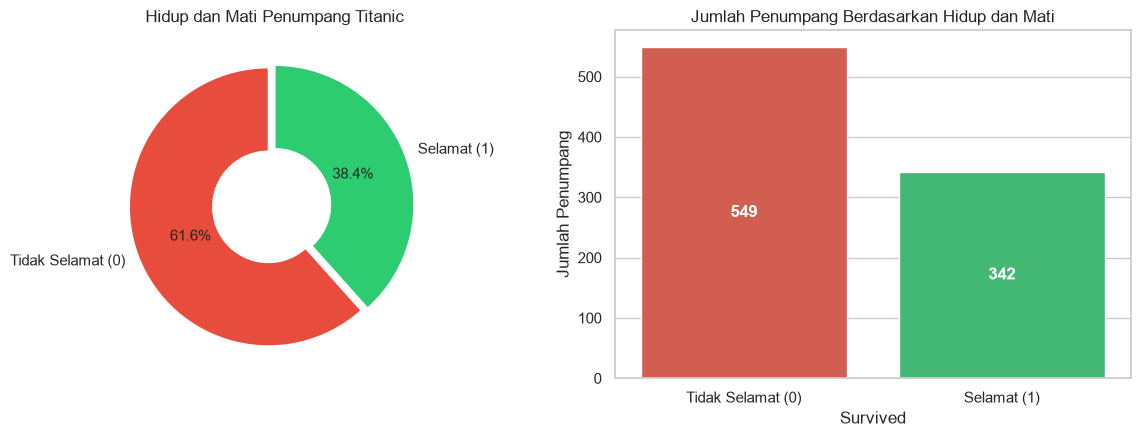

In [31]:
# Distribusi Variabel Target: Survived
survived_counts = df['Survived'].value_counts()
survived_pct = df['Survived'].value_counts(normalize=True) * 100

print("=== Distribusi Target (Survived) ===")
print(f"Tidak Selamat (0): {survived_counts[0]} ({survived_pct[0]:.2f}%)")
print(f"Selamat (1)      : {survived_counts[1]} ({survived_pct[1]:.2f}%)")

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# Donut chart
colors = ['#e74c3c', '#2ecc71']
ax[0].pie(survived_counts, labels=['Tidak Selamat (0)', 'Selamat (1)'], autopct='%1.1f%%',
          startangle=90, colors=colors, explode=(0.05, 0), wedgeprops=dict(width=0.6))
ax[0].set_title("Hidup dan Mati Penumpang Titanic")

# Bar chart
sns.countplot(data=df, x='Survived', palette=colors, ax=ax[1])
ax[1].set_title("Jumlah Penumpang Berdasarkan Hidup dan Mati")
ax[1].set_xticklabels(['Tidak Selamat (0)', 'Selamat (1)'])
ax[1].set_ylabel("Jumlah Penumpang")
for p in ax[1].patches:
    ax[1].annotate(f'{int(p.get_height())}', (p.get_x() + p.get_width() / 2., p.get_height() / 2),
                   ha='center', va='center', color='white', fontweight='bold', fontsize=12)

plt.tight_layout()
plt.show()


### 2.2 Visualisasi

Grafik berikut dipakai untuk melihat distribusi usia dan tarif, sebaran serta pencilan, dan hubungan fitur dengan status keselamatan. Histogram, boxplot, dan scatterplot memenuhi visualisasi utama; grafik kategori dan heatmap ditambahkan untuk membantu membandingkan kelompok.


#### A. Histograms: Distribusi Age & Fare Terhadap Status Kelangsungan Hidup

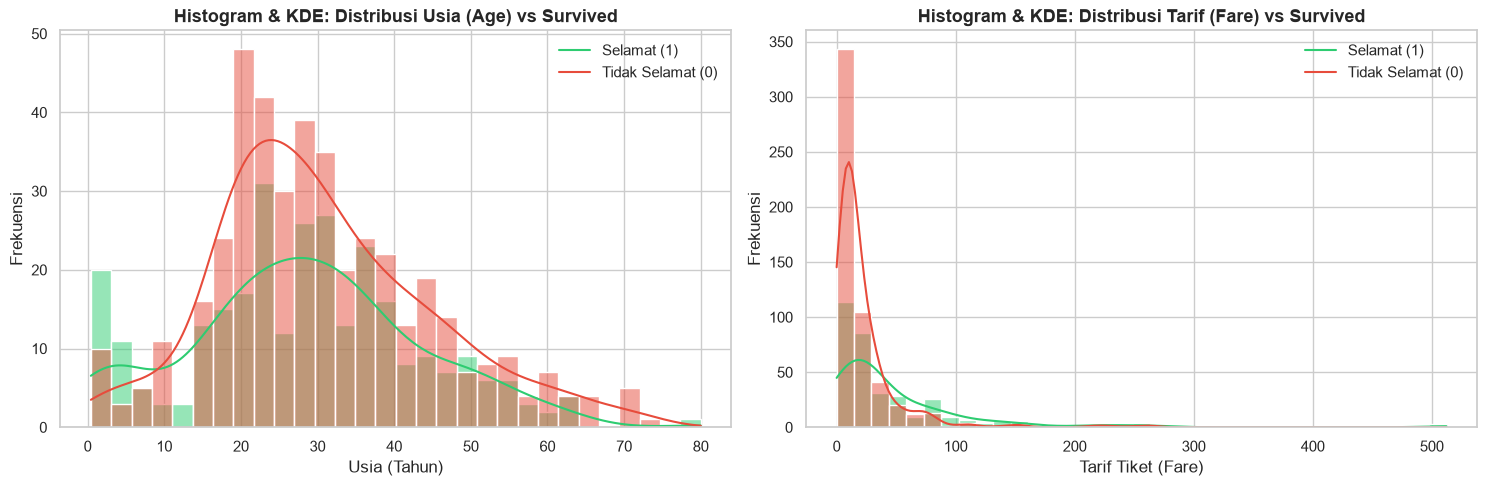

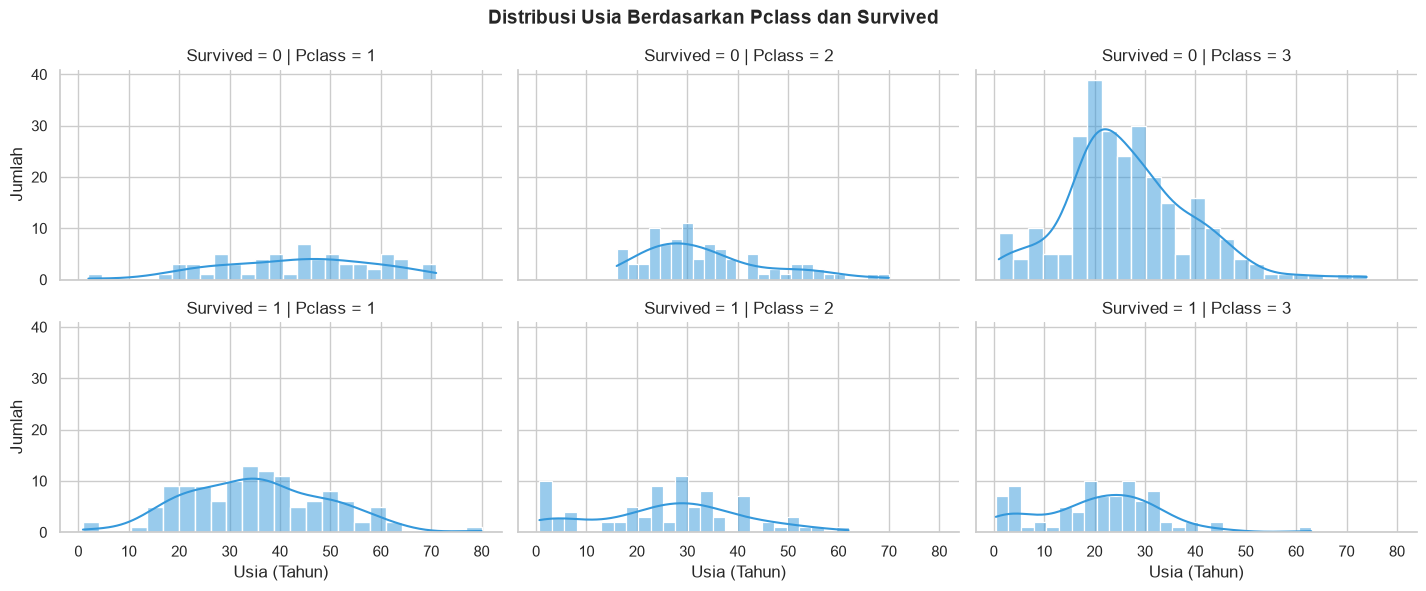

In [32]:
# 1. Histogram & KDE: Distribusi Usia (Age) dan Tarif (Fare) berdasarkan Kelangsungan Hidup
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Histogram Usia
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30, 
             palette=['#e74c3c', '#2ecc71'], ax=axes[0], alpha=0.5)
axes[0].set_title("Histogram & KDE: Distribusi Usia (Age) vs Survived", fontsize=13, fontweight='bold')
axes[0].set_xlabel("Usia (Tahun)")
axes[0].set_ylabel("Frekuensi")
axes[0].legend(['Selamat (1)', 'Tidak Selamat (0)'])

# Histogram Tarif (Fare)
sns.histplot(data=df, x='Fare', hue='Survived', kde=True, bins=35, 
             palette=['#e74c3c', '#2ecc71'], ax=axes[1], alpha=0.5)
axes[1].set_title("Histogram & KDE: Distribusi Tarif (Fare) vs Survived", fontsize=13, fontweight='bold')
axes[1].set_xlabel("Tarif Tiket (Fare)")
axes[1].set_ylabel("Frekuensi")
axes[1].legend(['Selamat (1)', 'Tidak Selamat (0)'])

plt.tight_layout()
plt.show()

# Histogram Age yang difasetkan berdasarkan Pclass
g = sns.FacetGrid(df, col='Pclass', row='Survived', height=3, aspect=1.6)
g.map(sns.histplot, 'Age', bins=25, color='#3498db', kde=True)
g.set_axis_labels("Usia (Tahun)", "Jumlah")
g.fig.subplots_adjust(top=0.88)
g.fig.suptitle("Distribusi Usia Berdasarkan Pclass dan Survived", fontsize=14, fontweight='bold')
plt.show()


#### B. Boxplot: sebaran dan pencilan

Boxplot membantu membandingkan median dan rentang usia/tarif antar kelompok. Grafik tarif juga memperlihatkan beberapa nilai tinggi yang jauh dari sebagian besar pengamatan.


C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\3091422389.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Pclass', y='Age', palette='Set2', ax=axes[0])


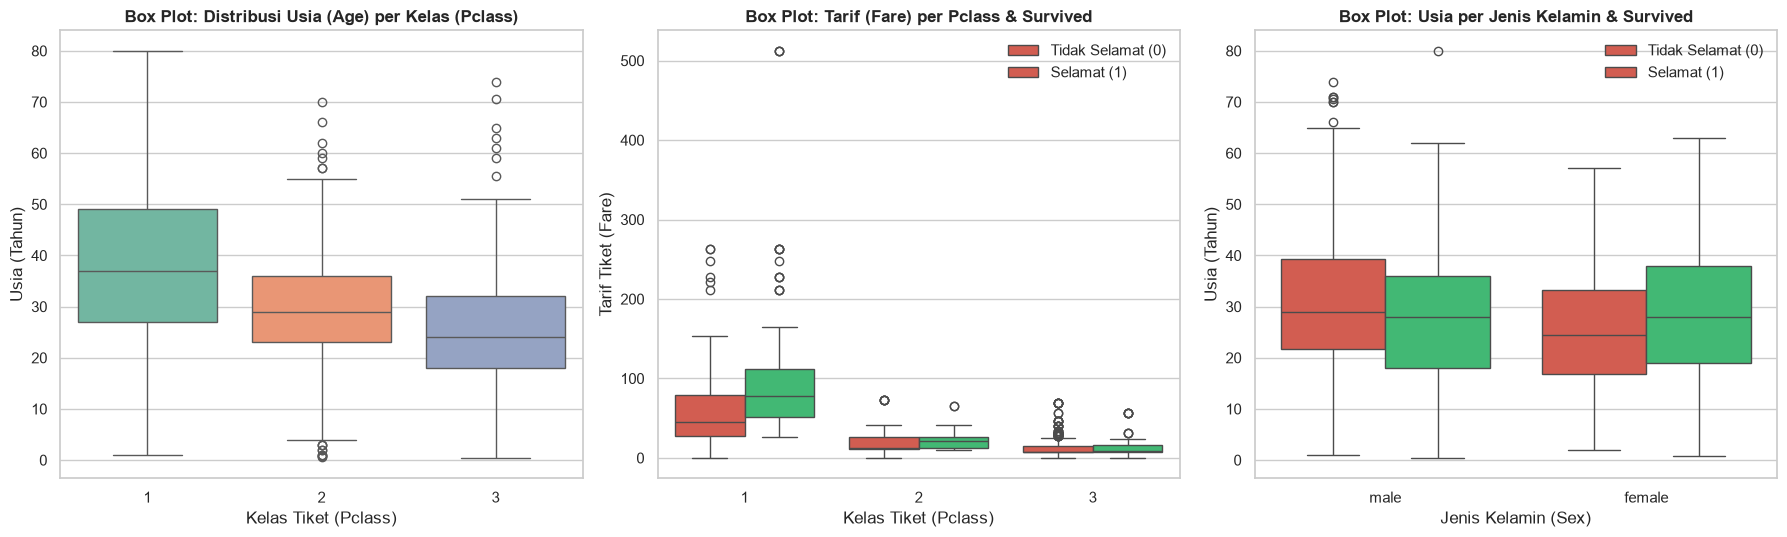

=== Median Usia Berdasarkan Pclass dan Sex ===


Sex,female,male
Pclass,,
1,35.0,40.0
2,28.0,30.0
3,21.5,25.0


In [33]:
# 2. Box Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# Boxplot Usia berdasarkan Pclass (Justifikasi untuk pengisian missing value Age)
sns.boxplot(data=df, x='Pclass', y='Age', palette='Set2', ax=axes[0])
axes[0].set_title("Box Plot: Distribusi Usia (Age) per Kelas (Pclass)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Kelas Tiket (Pclass)")
axes[0].set_ylabel("Usia (Tahun)")

# Boxplot Fare berdasarkan Pclass dan Survived (Menampilkan outliers pada Fare)
sns.boxplot(data=df, x='Pclass', y='Fare', hue='Survived', palette=['#e74c3c', '#2ecc71'], ax=axes[1])
axes[1].set_title("Box Plot: Tarif (Fare) per Pclass & Survived", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Kelas Tiket (Pclass)")
axes[1].set_ylabel("Tarif Tiket (Fare)")
axes[1].legend(['Tidak Selamat (0)', 'Selamat (1)'])

# Boxplot Usia berdasarkan Survived dan Sex
sns.boxplot(data=df, x='Sex', y='Age', hue='Survived', palette=['#e74c3c', '#2ecc71'], ax=axes[2])
axes[2].set_title("Box Plot: Usia per Jenis Kelamin & Survived", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Jenis Kelamin (Sex)")
axes[2].set_ylabel("Usia (Tahun)")
axes[2].legend(['Tidak Selamat (0)', 'Selamat (1)'])

plt.tight_layout()
plt.show()

# Menampilkan median usia per Pclass dan Sex untuk referensi imputasi
print("=== Median Usia Berdasarkan Pclass dan Sex ===")
display(df.groupby(['Pclass', 'Sex'])['Age'].median().unstack())


#### C. Scatter Plots: Hubungan Multivariat (Age vs Fare)
Scatter plot menampilkan relasi antara dua fitur numerik kontinu (`Age` dan `Fare`) dengan warna (*hue*) mewakili status `Survived` dan bentuk penanda (*style*) mewakili `Sex`.


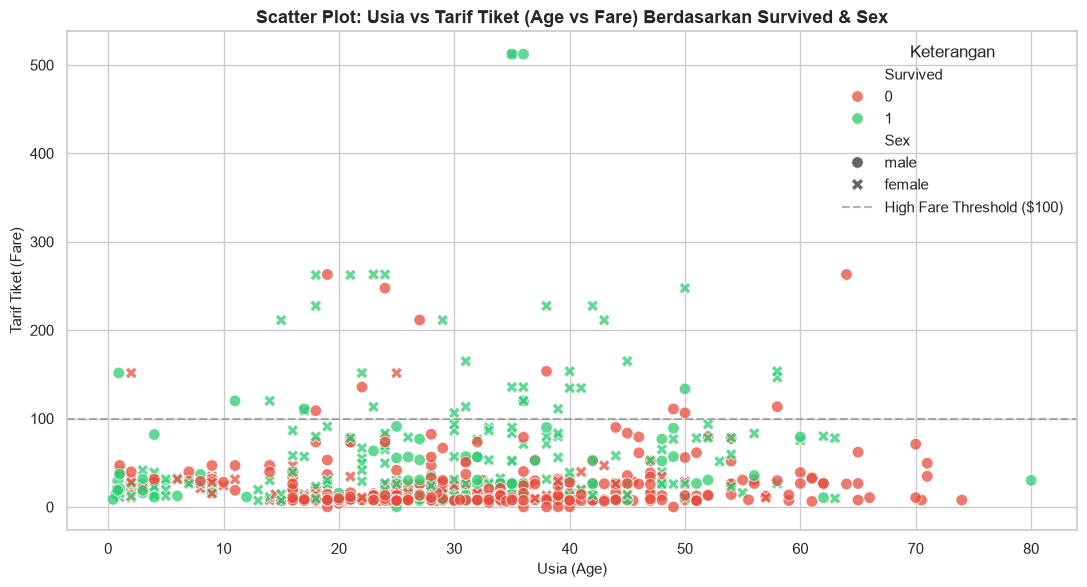

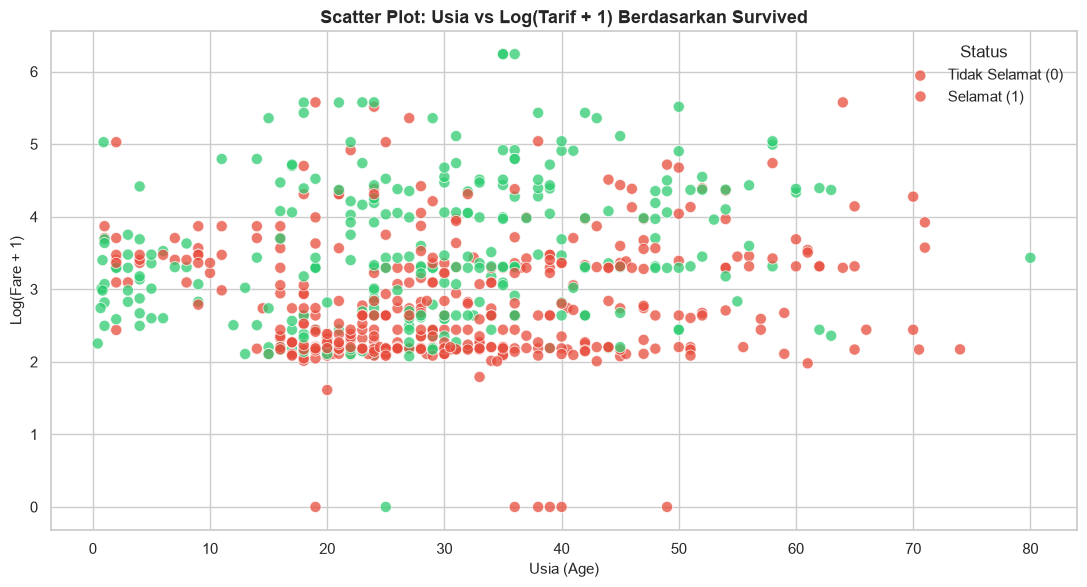

In [34]:
# 3. Scatter Plot: Usia vs Tarif berdasarkan Status Keselamatan
fig, ax = plt.subplots(figsize=(11, 6))

sns.scatterplot(
    data=df, 
    x='Age', 
    y='Fare', 
    hue='Survived', 
    style='Sex',
    palette=['#e74c3c', '#2ecc71'], 
    alpha=0.75, 
    s=70, 
    ax=ax
)

ax.set_title("Scatter Plot: Usia vs Tarif Tiket (Age vs Fare) Berdasarkan Survived & Sex", fontsize=13, fontweight='bold')
ax.set_xlabel("Usia (Age)", fontsize=11)
ax.set_ylabel("Tarif Tiket (Fare)", fontsize=11)
ax.axhline(100, color='gray', linestyle='--', alpha=0.6, label='High Fare Threshold ($100)')
ax.legend(title='Keterangan', loc='upper right')

plt.tight_layout()
plt.show()

# Scatter Plot dengan Skala Logaritmik untuk Fare agar persebaran terlihat lebih jelas
fig, ax = plt.subplots(figsize=(11, 6))
df_temp = df.copy()
df_temp['Log_Fare'] = np.log1p(df_temp['Fare'])

sns.scatterplot(
    data=df_temp, 
    x='Age', 
    y='Log_Fare', 
    hue='Survived', 
    palette=['#e74c3c', '#2ecc71'],
    alpha=0.75, 
    s=65, 
    ax=ax
)
ax.set_title("Scatter Plot: Usia vs Log(Tarif + 1) Berdasarkan Survived", fontsize=13, fontweight='bold')
ax.set_xlabel("Usia (Age)", fontsize=11)
ax.set_ylabel("Log(Fare + 1)", fontsize=11)
ax.legend(['Tidak Selamat (0)', 'Selamat (1)'], title='Status', loc='upper right')

plt.tight_layout()
plt.show()


### 2.3 Pola yang Terlihat

Dari ringkasan dan grafik, beberapa perbedaan antar kelompok tampak cukup jelas:

- Tingkat keselamatan perempuan lebih tinggi daripada laki-laki.
- Survival rate cenderung lebih tinggi pada penumpang kelas 1 dibanding kelas 3; tarif juga tampak berkaitan dengan kelas tiket.
- Perbedaan berdasarkan jenis kelamin terlihat di dalam kelompok kelas, sehingga ada baiknya melihat kedua fitur bersama-sama.
- Distribusi usia kelompok yang selamat dan tidak selamat saling tumpang tindih, meskipun anak-anak tampak memiliki pola yang berbeda dari orang dewasa.
- Ukuran keluarga dan pelabuhan keberangkatan dapat memberi konteks tambahan, tetapi hubungan pada grafik ini tidak membuktikan sebab-akibat.

Pola-pola tersebut berguna sebagai petunjuk awal, bukan jaminan bahwa fitur tertentu menyebabkan seseorang selamat. Nilai persentase sebaiknya dibaca dari tabel/grafik hasil eksekusi notebook.


---
## 3. Preprocessing

Tahap ini menyiapkan data sebelum pemodelan: membersihkan nilai kosong, membuat fitur baru, memilih kolom yang digunakan, mengubah kategori menjadi angka, dan menstandarkan fitur numerik.


### 3.1 Data Cleaning: Menangani Nilai Kosong

- `Cabin` memiliki banyak nilai kosong. Kolom ini dihapus untuk pemodelan dasar; analisis lanjutan masih bisa mencoba membuat indikator apakah kabin tercatat.
- `Age` diisi dengan median kelompok `Pclass` dan `Title` agar perbedaan usia antar kelompok tetap diperhatikan. Jika median grup tidak tersedia, digunakan median keseluruhan.
- `Embarked` diisi dengan kategori yang paling sering muncul karena hanya sedikit nilainya yang kosong.
- `Title` diekstrak dari `Name` terlebih dahulu. Setelah itu `PassengerId`, `Ticket`, dan `Name` mentah tidak digunakan sebagai fitur model dasar.

Cara ini mempertahankan baris data. Untuk evaluasi yang lebih ketat, nilai imputasi sebaiknya dihitung dari data latih saja melalui pipeline.


#### A. Feature Engineering: Mengambil gelar dari nama

Gelar diambil dari kolom `Name` untuk membantu pengelompokan usia dan menjadi fitur kategori.

In [35]:
# Membuat salinan DataFrame untuk pra-pemrosesan
df_clean = df.copy()

# 1. Ekstraksi Fitur Tambahan: Title dari Name
df_clean['Title'] = df_clean['Name'].str.extract(' ([A-Za-z]+)\.', expand=False)

# Mengelompokkan gelar langka ke dalam kategori umum
rare_titles = ['Lady', 'Countess', 'Capt', 'Col', 'Don', 'Dr', 'Major', 'Rev', 'Sir', 'Jonkheer', 'Dona']
df_clean['Title'] = df_clean['Title'].replace(rare_titles, 'Rare')
df_clean['Title'] = df_clean['Title'].replace('Mlle', 'Miss')
df_clean['Title'] = df_clean['Title'].replace('Ms', 'Miss')
df_clean['Title'] = df_clean['Title'].replace('Mme', 'Mrs')

print("Distribusi Title:")
print(df_clean['Title'].value_counts())


Distribusi Title:
Title
Mr        517
Miss      185
Mrs       126
Master     40
Rare       23
Name: count, dtype: int64


#### B. Data Cleaning: Mengisi nilai `Age` yang kosong

Usia yang kosong diisi menggunakan median berdasarkan kombinasi kelas tiket dan gelar.

In [36]:
# 2. Imputasi Age berdasarkan Pclass dan Title/Sex
# Menghitung median usia per kombinasi Pclass dan Title
age_medians = df_clean.groupby(['Pclass', 'Title'])['Age'].median()
print("=== Median Usia per Pclass & Title ===")
print(age_medians)

# Mengisi missing values pada Age menggunakan median grup masing-masing
df_clean['Age'] = df_clean.groupby(['Pclass', 'Title'])['Age'].transform(
    lambda x: x.fillna(x.median())
)

# Jika masih ada sisa (karena grup langka), isi dengan median global
df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)


=== Median Usia per Pclass & Title ===
Pclass  Title 
1       Master     4.0
        Miss      30.0
        Mr        40.0
        Mrs       40.0
        Rare      48.5
2       Master     1.0
        Miss      24.0
        Mr        31.0
        Mrs       32.0
        Rare      46.5
3       Master     4.0
        Miss      18.0
        Mr        26.0
        Mrs       31.0
Name: Age, dtype: float64


C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\633066353.py:13: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_clean['Age'].fillna(df_clean['Age'].median(), inplace=True)


0      22.0
1      38.0
2      26.0
3      35.0
4      35.0
       ... 
886    27.0
887    19.0
888    18.0
889    26.0
890    32.0
Name: Age, Length: 891, dtype: float64

#### C. Data Cleaning: Mengisi nilai `Embarked` yang kosong

In [37]:
# 3. Imputasi Embarked dengan Modus ('S')
mode_embarked = df_clean['Embarked'].mode()[0]
df_clean['Embarked'].fillna(mode_embarked, inplace=True)
print(f"Missing values pada Embarked berhasil diisi dengan modus: '{mode_embarked}'")


Missing values pada Embarked berhasil diisi dengan modus: 'S'


C:\Users\David NS\AppData\Local\Temp\ipykernel_27132\3937740055.py:3: ChainedAssignmentError: A value is being set on a copy of a DataFrame or Series through chained assignment using an inplace method.
Such inplace method never works to update the original DataFrame or Series, because the intermediate object on which we are setting values always behaves as a copy (due to Copy-on-Write).

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' instead, to perform the operation inplace on the original object, or try to avoid an inplace operation using 'df[col] = df[col].method(value)'.

See the documentation for a more detailed explanation: https://pandas.pydata.org/pandas-docs/stable/user_guide/copy_on_write.html
  df_clean['Embarked'].fillna(mode_embarked, inplace=True)


#### C. Feature Engineering dan pemilihan kolom

Buat `FamilySize` dari jumlah saudara/pasangan dan orang tua/anak. Setelah `Title` diekstrak, kolom identitas/teks yang tidak dipakai untuk model dihapus.


In [38]:
# 4. Feature Engineering: FamilySize & IsAlone
df_clean['FamilySize'] = df_clean['SibSp'] + df_clean['Parch'] + 1

# 5. Drop kolom yang tidak relevan / missing berlebih
columns_to_drop = ['PassengerId', 'Ticket', 'Cabin', 'Name']
df_clean.drop(columns=columns_to_drop, inplace=True)

print("=== Verifikasi Missing Values Setelah Cleaning ===")
print(df_clean.isnull().sum())
print(f"\nDimensi dataset setelah pembersihan: {df_clean.shape}")
df_clean.head()


=== Verifikasi Missing Values Setelah Cleaning ===
Survived      0
Pclass        0
Sex           0
Age           0
SibSp         0
Parch         0
Fare          0
Embarked      2
Title         0
FamilySize    0
dtype: int64

Dimensi dataset setelah pembersihan: (891, 10)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize
0,0,3,male,22.0,1,0,7.2500,S,Mr,2
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2
2,1,3,female,26.0,0,0,7.9250,S,Miss,1
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2
4,0,3,male,35.0,0,0,8.0500,S,Mr,1


### 3.3 Encoding: Mengubah Fitur Kategorikal

- `Sex` diubah menjadi angka biner (`male` = 0, `female` = 1), karena hanya memiliki dua kategori.
- `Embarked` dan `Title` diubah dengan one-hot encoding. Keduanya merupakan kategori tanpa urutan alami, sehingga tidak tepat diberi angka berurutan seolah-olah ada tingkatan.
- `Pclass` dipertahankan sebagai angka ordinal. Angka 1 menandakan kelas tertinggi dan 3 kelas terendah; hubungan ini perlu diingat saat menafsirkan koefisien model.


In [39]:
df_encoded = df_clean.copy()
df_encoded['Sex'] = df_encoded['Sex'].map({'male': 0, 'female': 1})
df_encoded = pd.get_dummies(df_encoded, columns=['Embarked', 'Title'], drop_first=True, dtype=int)
df_encoded.head()


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,22.0,1,0,7.2500,2,0,1,0,1,0,0
1,1,1,1,38.0,1,0,71.2833,2,0,0,0,0,1,0
2,1,3,1,26.0,0,0,7.9250,1,0,1,1,0,0,0
3,1,1,1,35.0,1,0,53.1000,2,0,1,0,0,1,0
4,0,3,0,35.0,0,0,8.0500,1,0,1,0,1,0,0


### 3.4 Feature Scaling

StandardScaler dipilih agar skala Age, Fare, dan FamilySize lebih sebanding untuk Logistic Regression. Grafik berikut membandingkan sebaran sebelum dan sesudah scaling.


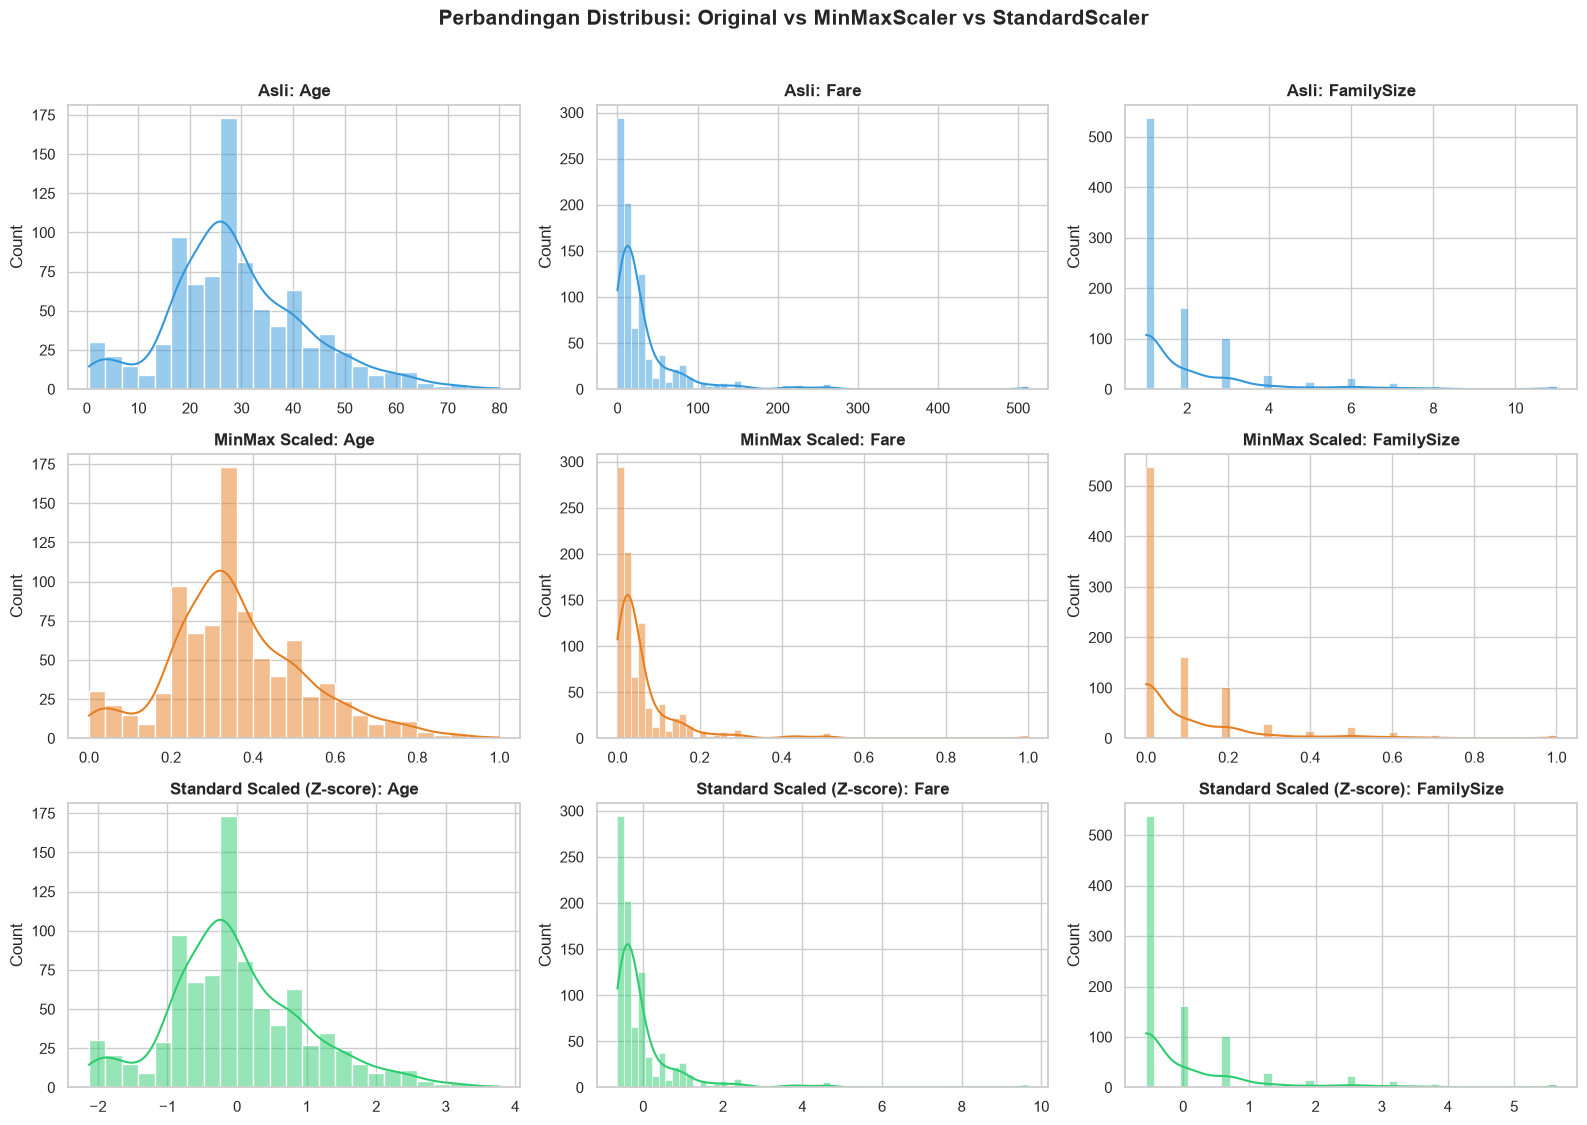

In [40]:
# Pemisahan Fitur Numerik untuk Scaling
num_features = ['Age', 'Fare', 'FamilySize']

# Inisialisasi Scaler
std_scaler = StandardScaler()
minmax_scaler = MinMaxScaler()

# Visualisasi Perbandingan: Sebelum Scaling vs Min-Max vs Standard Scaling
fig, axes = plt.subplots(3, 3, figsize=(16, 11))

# Sebelum Scaling
for i, col in enumerate(num_features):
    sns.histplot(df_encoded[col], kde=True, ax=axes[0, i], color='#3498db')
    axes[0, i].set_title(f"Asli: {col}", fontweight='bold')
    axes[0, i].set_xlabel("")

# Setelah MinMaxScaler
df_minmax = df_encoded.copy()
df_minmax[num_features] = minmax_scaler.fit_transform(df_minmax[num_features])
for i, col in enumerate(num_features):
    sns.histplot(df_minmax[col], kde=True, ax=axes[1, i], color='#e67e22')
    axes[1, i].set_title(f"MinMax Scaled: {col}", fontweight='bold')
    axes[1, i].set_xlabel("")

# Setelah StandardScaler
df_scaled = df_encoded.copy()
df_scaled[num_features] = std_scaler.fit_transform(df_scaled[num_features])
for i, col in enumerate(num_features):
    sns.histplot(df_scaled[col], kde=True, ax=axes[2, i], color='#2ecc71')
    axes[2, i].set_title(f"Standard Scaled (Z-score): {col}", fontweight='bold')
    axes[2, i].set_xlabel("")

plt.suptitle("Perbandingan Distribusi: Original vs MinMaxScaler vs StandardScaler", fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


In [41]:
# Memeriksa statistik deskriptif data setelah standarisasi (StandardScaler)
print("=== Statistik Fitur Numerik Setelah Standarisasi (Mean ~ 0, Std ~ 1) ===")
df_scaled[num_features].describe().round(4)


=== Statistik Fitur Numerik Setelah Standarisasi (Mean ~ 0, Std ~ 1) ===


,Age,Fare,FamilySize
count,891.0000,891.0000,891.0000
mean,0.0000,0.0000,-0.0000
std,1.0006,1.0006,1.0006
min,-2.1297,-0.6484,-0.5610
25%,-0.6034,-0.4891,-0.5610
50%,-0.2325,-0.3574,-0.5610
75%,0.5647,-0.0242,0.0592
max,3.7724,9.6672,5.6404


In [42]:
# Menampilkan 5 baris pertama dataset final yang telah selesai di-preprocess
print("=== Final Preprocessed Dataset (Siap untuk Machine Learning) ===")
print(f"Shape: {df_scaled.shape}")
df_scaled.head()


=== Final Preprocessed Dataset (Siap untuk Machine Learning) ===
Shape: (891, 14)


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,FamilySize,Embarked_Q,Embarked_S,Title_Miss,Title_Mr,Title_Mrs,Title_Rare
0,0,3,0,-0.529205,1,0,-0.502445,0.059160,0,1,0,1,0,0
1,1,1,1,0.657447,1,0,0.786845,0.059160,0,0,0,0,1,0
2,1,3,1,-0.232542,0,0,-0.488854,-0.560975,0,1,1,0,0,0
3,1,1,1,0.434950,1,0,0.420730,0.059160,0,1,0,0,1,0
4,0,3,0,0.434950,0,0,-0.486337,-0.560975,0,1,0,1,0,0


## 4. Modelling

Data dibagi menjadi 70% data latih dan 30% data uji. Model yang digunakan adalah Logistic Regression.


In [43]:
# Pisahkan fitur dan target, lalu buat train-test split
X = df_encoded.drop(columns=['Survived']).copy()
y = df_encoded['Survived']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# Fit scaler hanya dari data latih agar data uji tidak bocor ke proses training
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
scaler_model = StandardScaler()
X_train_scaled[num_features] = scaler_model.fit_transform(X_train[num_features])
X_test_scaled[num_features] = scaler_model.transform(X_test[num_features])

print(f"Data latih: {X_train.shape[0]} baris")
print(f"Data uji  : {X_test.shape[0]} baris")


Data latih: 623 baris
Data uji  : 268 baris


### 4.1 Logistic Regression


Accuracy : 0.821
Precision: 0.778
Recall   : 0.748
ROC-AUC  : 0.877

Confusion matrix:
[[143  22]
 [ 26  77]]
TN = tidak selamat diprediksi tidak selamat
FP = tidak selamat diprediksi selamat
FN = selamat diprediksi tidak selamat
TP = selamat diprediksi selamat


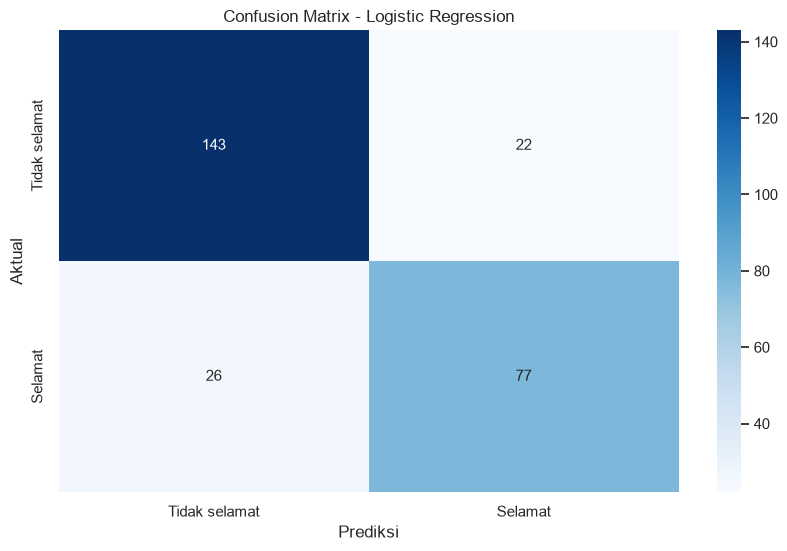

In [44]:
# Latih model dan buat prediksi pada data uji
model = LogisticRegression(max_iter=1000, random_state=42)
model.fit(X_train_scaled, y_train)
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)[:, 1]

# Tampilkan metrik evaluasi
print(f"Accuracy : {accuracy_score(y_test, y_pred):.3f}")
print(f"Precision: {precision_score(y_test, y_pred):.3f}")
print(f"Recall   : {recall_score(y_test, y_pred):.3f}")
print(f"ROC-AUC  : {roc_auc_score(y_test, y_prob):.3f}")

# Confusion matrix (baris = aktual, kolom = prediksi)
cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix:")
print(cm)
print("TN = tidak selamat diprediksi tidak selamat")
print("FP = tidak selamat diprediksi selamat")
print("FN = selamat diprediksi tidak selamat")
print("TP = selamat diprediksi selamat")

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Tidak selamat', 'Selamat'],
            yticklabels=['Tidak selamat', 'Selamat'])
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title('Confusion Matrix - Logistic Regression')
plt.show()


---
## 5. Evaluation

Kinerja Logistic Regression diperiksa pada data uji menggunakan accuracy, precision, recall, ROC-AUC, dan confusion matrix.


## 6. Ringkasan singkat

| Tahap | Yang dilakukan |
|---|---|
| EDA | Memeriksa tipe data, statistik ringkas, nilai kosong, distribusi target, dan pola antar fitur. |
| Visualisasi | Histogram, boxplot, dan scatterplot. |
| Temuan awal | Jenis kelamin dan kelas tiket menunjukkan perbedaan survival rate yang jelas pada data ini. Usia, tarif, ukuran keluarga, dan pelabuhan juga ditinjau. |
| Data kosong | `Cabin` dihapus; `Age` diisi dengan median kelompok; `Embarked` diisi modus. |
| Encoding | `Sex` dipetakan ke angka biner; `Embarked` dan `Title` di-one-hot encode; `Pclass` dipertahankan sebagai ordinal. |
| Model dan evaluasi | Logistic Regression diuji dengan pembagian data 70:30 dan metrik evaluasi yang diminta. |

Akurasi dan metrik lainnya dapat dilihat pada output laporan klasifikasi di atas. Nilai tersebut bergantung pada data dan pembagian train-test yang digunakan.
